# ML-CAP-01 Capstone — March Signals for Search Review

**Lane:** CTR / Engagement Opportunity Scoring  
**Author:** Imam Hossain Safin  
**Question:** Can March search-performance signals help rank pages for a human review when April clicks fall by at least 20%?

This notebook documents the analysis behind the repository report and runs the same reproducible script used to build it. It is designed to run top to bottom in Colab after you accept access to the gated dataset and add a Hugging Face **read** token in the `HF_TOKEN` environment variable.

> Public-safety rule: the token is read from an environment variable; never paste it into a cell. The analysis writes aggregate metrics and charts only, not client/page IDs or row-level predictions.

## 1. Question and decision

Editors cannot review every page equally deeply. The decision supported here is **which eligible client-content items to inspect first** when April clicks are at least 20% below March clicks. The model's score is a review-priority signal; a person must still check measurement coverage, seasonality, search-result context, and page relevance before editing anything.

A false positive costs review time; a false negative may leave a decline unnoticed. This analysis does not publish, prune, or automatically change content.

In [1]:
question = "Can March-only signals rank pages with an April click-decline proxy for human review?"
decision = "Prioritize an editorial/search-result review queue; never edit automatically."
print("Research question:", question)
print("Decision supported:", decision)

Research question: Can March-only signals rank pages with an April click-decline proxy for human review?
Decision supported: Prioritize an editorial/search-result review queue; never edit automatically.


## 2. Data, eligibility, and privacy

**Source:** FlyRank's gated `FlyRank/internship-warehouse` release, build v20260703. The fact-table grain is report date × pseudonymous client × pseudonymous content item. The analysis reads only the **March 2026** feature partition and **April 2026** label partition from `fact_content_daily_performance`; it does not scan the full release or use the final-month sample table.

Before defining a shared March cutoff, the query checks `dim_clients.gsc_data_start`. Clients with missing start dates or starts after March 1 are excluded. Eligible rows also need `gsc_data_available IS TRUE`, active client-level April GSC coverage, positive March clicks, and at least 100 March impressions. The daily date/client/content grain is checked for duplicates before monthly aggregation.

March impressions, clicks, CTR, and average position are the only candidate model inputs. Client/content IDs are join and grouping keys only. April outcomes, trend fields, product decisions, GA4 fields, names, domains, URLs, titles, and raw search queries are excluded. If an eligible client has April GSC coverage but a specific item has no April row, its April clicks are treated as zero; that assumption is called out as a limitation. No row-level export is saved.

## 3. Reproducible setup and gated access

The setup cell finds or clones the target repository, installs its pinned-minimum requirements, then reads `HF_TOKEN` only from the process environment. The token itself is never printed or written to disk. If access is missing, first accept the dataset terms and then set the read token in the process environment.

In [2]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Safin44/my-flyrank-ml-internship.git"
repo_candidates = [Path.cwd(), Path("/content/my-flyrank-ml-internship")]
ROOT = next((p.resolve() for p in repo_candidates if (p / "work/scripts/run_capstone.py").exists()), None)
if ROOT is None:
    ROOT = Path("/content/my-flyrank-ml-internship")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
ROOT = ROOT.resolve()
os.chdir(ROOT)

pip_env = os.environ.copy()
pip_env["PIP_DISABLE_PIP_VERSION_CHECK"] = "1"
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True, env=pip_env)

token = os.environ.get("HF_TOKEN")
if not token:
    raise RuntimeError("Set the Hugging Face read token in the HF_TOKEN environment variable before running this notebook.")
del token
print("Repository and dependencies are ready; private dataset access is configured (token hidden).")

Repository and dependencies are ready; private dataset access is configured (token hidden).


## 4. Methodology and leakage checks

The target is **1 when April clicks are ≤ 80% of March clicks**. It is a retrospective decline proxy, not a label that proves content needs a refresh.

- **Eligibility:** March impressions ≥ 100 and March clicks > 0; known client GSC start on/before March 1; active April GSC coverage. A missing item-level April row is treated as zero clicks only for a client active in April.
- **Baseline:** within March average-position bands, compare a page's March CTR with the training-client median CTR for that band; weight a positive CTR gap by `log(1 + impressions)`.
- **Model:** median imputation, standardization, and class-balanced logistic regression (`C=1`, `max_iter=2000`, seed 42); four March-only inputs: `log1p(impressions)`, `log1p(clicks)`, CTR, and mean position.
- **Validation:** reproducible `GroupShuffleSplit`, 75/25 by client, seed 42. A client cannot appear in both partitions. Both methods are measured on the same held-out rows.
- **Leakage controls:** April values define the label only; client/content IDs are never features; product/trend/GA4 fields are excluded. The script checks daily grain before aggregating and writes no row-level scores.

In [3]:
# Run the single, reproducible pipeline. It reads only the March and April partitions.
run = subprocess.run(
    [sys.executable, str(ROOT / "work/scripts/run_capstone.py"), "--source", "warehouse"],
    cwd=ROOT,
    env=os.environ.copy(),
    text=True,
    capture_output=True,
)
if run.stdout:
    print(run.stdout)
if run.returncode != 0:
    error_text = run.stderr or ""
    secret_value = os.environ.get("HF_TOKEN", "")
    if secret_value:
        error_text = error_text.replace(secret_value, "[REDACTED]")
    print(error_text[-6000:])
    raise RuntimeError(f"Capstone pipeline failed with exit code {run.returncode}.")

import json
import pandas as pd
from IPython.display import display, Image, Markdown

metrics = json.loads((ROOT / "work/outputs/capstone_metrics.json").read_text(encoding="utf-8"))
print("Loaded saved aggregate metrics and action summary.")

Querying only the March 2026 feature and April 2026 label partitions…
Warehouse capstone complete (March features, April label).
Eligible items: 63,498; train/test items: 48,820/14,678.
Grouped split: 26 train clients, 9 test clients; overlap=0.
Positive-label base rate: 72.537%; majority-class rate: 72.537%.
Model AP=0.7594, P@50=0.960, ROC-AUC=0.5301.
Baseline AP=0.7076, P@50=0.680, ROC-AUC=0.4772.
Only aggregate metrics, action counts, and charts were written; no IDs or row-level predictions were exported.



Loaded saved aggregate metrics and action summary.


## 5. Results — same held-out clients, same labels

Average precision is shown beside the test positive rate; Precision@K is not meaningful without a base-rate reference. ROC-AUC indicates whether ranking separates positives from negatives across thresholds. The script also reports the CTR-gap baseline and a no-discrimination reference.

In [4]:
split = metrics["split"]
model = metrics["model_metrics"]
baseline = metrics["baseline_metrics"]
random_ref = metrics["base_rate_reference"]

evaluation = pd.DataFrame([
    {"Method": "Class-balanced logistic regression", **model},
    {"Method": "March CTR-gap baseline", **baseline},
    {"Method": "No-discrimination reference", **random_ref},
]).set_index("Method")
display(evaluation.round(3))

print(f"Rows: {split['train_rows']:,} train / {split['test_rows']:,} held out")
print(f"Clients: {split['train_clients']} train / {split['test_clients']} held out; overlap = {split['client_overlap']}")
print(f"Positive-label rate: {split['train_positive_rate']:.1%} train vs {split['test_positive_rate']:.1%} test")

,average_precision,precision_at_10,precision_at_50,roc_auc,description
Method,,,,,
Class-balanced logistic regression,0.759,1.000,0.960,0.530,NaN
March CTR-gap baseline,0.708,0.900,0.680,0.477,NaN
No-discrimination reference,0.725,0.725,0.725,0.500,Expected random ranking / no-discrimination re...


Rows: 48,820 train / 14,678 held out
Clients: 26 train / 9 held out; overlap = 0
Positive-label rate: 55.9% train vs 72.5% test


### Readout

This is a **modest improvement in average precision**, not a strong generalization result. Test average precision is compared with both the baseline and the no-discrimination reference; ROC-AUC is also shown because it is near chance here. The held-out client prevalence is materially higher than the training prevalence, so the one client split has visible distribution shift. Treat the scores as weak, directional review evidence only.

In [5]:
overall = metrics["target"]["positive_rate"]
test_rate = split["test_positive_rate"]
ap_lift_vs_random = model["average_precision"] - random_ref["average_precision"]
print(f"Overall eligible-cohort decline-proxy rate: {overall:.1%}")
print(f"Held-out positive rate / random AP reference: {test_rate:.1%}")
print(f"Model AP minus no-discrimination AP: {ap_lift_vs_random:+.3f}")
print(f"Model ROC-AUC: {model['roc_auc']:.3f} (0.500 is chance-level ranking)")

Overall eligible-cohort decline-proxy rate: 59.8%
Held-out positive rate / random AP reference: 72.5%
Model AP minus no-discrimination AP: +0.034
Model ROC-AUC: 0.530 (0.500 is chance-level ranking)


### Sensitivity and held-out action summary

The label rate changes as low-impression items are removed. The main run uses the 100-impression floor. The action summary below describes only the held-out top-risk set and is descriptive, not an independently validated second test.

In [6]:
sensitivity = pd.DataFrame(metrics["label_sensitivity"]).rename(columns={
    "min_march_impressions": "Minimum March impressions",
    "eligible_rows": "Eligible items",
    "positive_rate": "Positive-label rate",
})
sensitivity["Positive-label rate"] = sensitivity["Positive-label rate"].map(lambda x: f"{x:.1%}")
display(sensitivity)

actions = metrics["action_summary"]
display(pd.DataFrame([
    {"Held-out top-risk items summarized": actions["ranked_items_summarized"]},
    {"Items with the decline proxy": actions["decline_proxy_items"]},
    {"Positive-proxy share": f"{actions['positive_proxy_share']:.1%}"},
    {"Median March impressions": actions["median_march_impressions"]},
]))
print("Position-band counts in this held-out top-risk set:", actions["position_band_counts"])

,Eligible items,Minimum March impressions,Positive-label rate
0,68624,1,61.5%
1,63498,100,59.8%
2,51062,500,57.5%


,Held-out top-risk items summarized,Items with the decline proxy,Positive-proxy share,Median March impressions
0,100.0,NaN,NaN,NaN
1,NaN,94.0,NaN,NaN
2,NaN,NaN,94.0%,NaN
3,NaN,NaN,NaN,168.0


Position-band counts in this held-out top-risk set: {'13–20': 0, '4–5': 0, '6–8': 0, '9–12': 0, '>20': 100, 'unknown': 0, '≤3': 0}


## 6. Charts and interpretation

The precision–recall chart shows how precision changes as recall increases. The Precision@K chart compares model and baseline with the held-out base rate. Permutation importance describes how much held-out average precision changes when one feature is shuffled; correlated search features can share importance, and none of these measurements are causal.

capstone precision recall.png


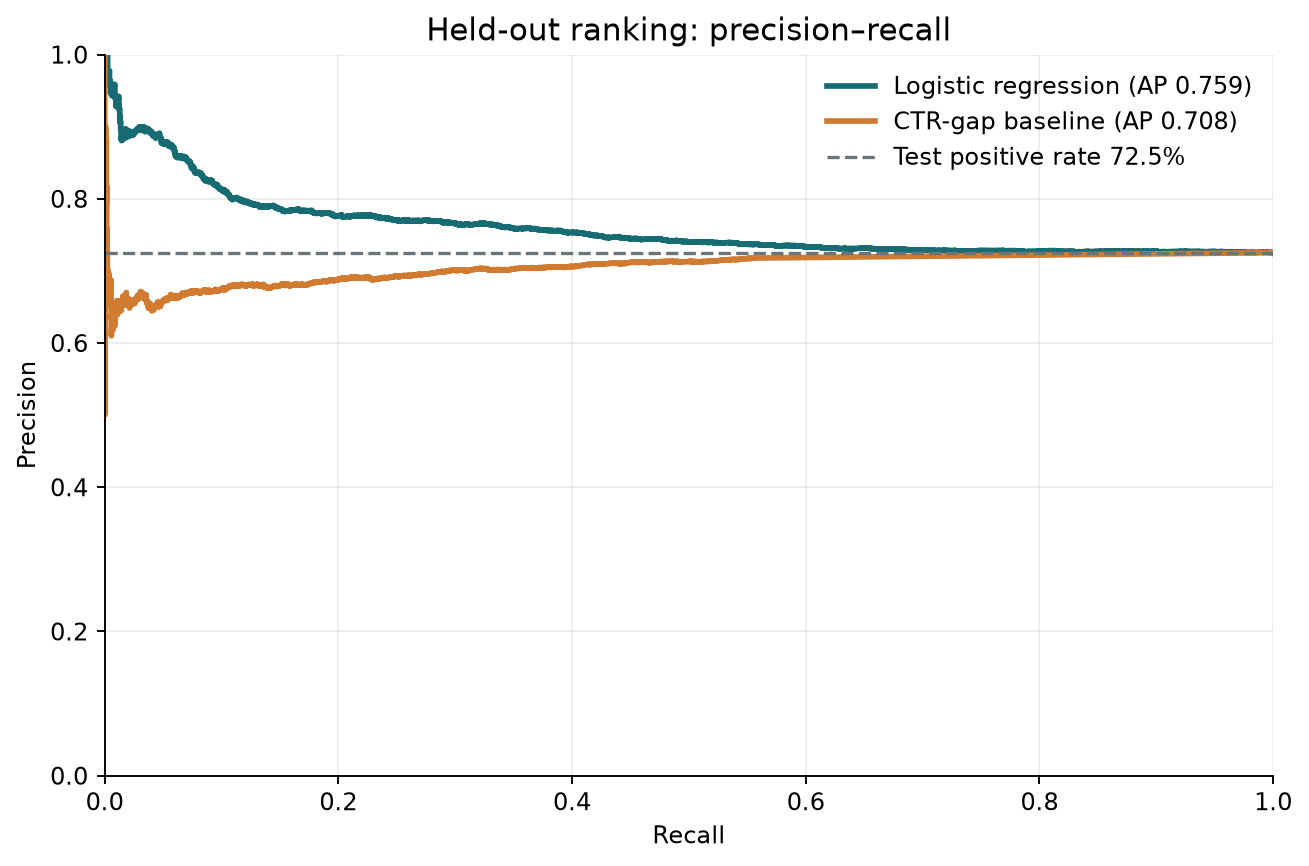

capstone precision at k.png


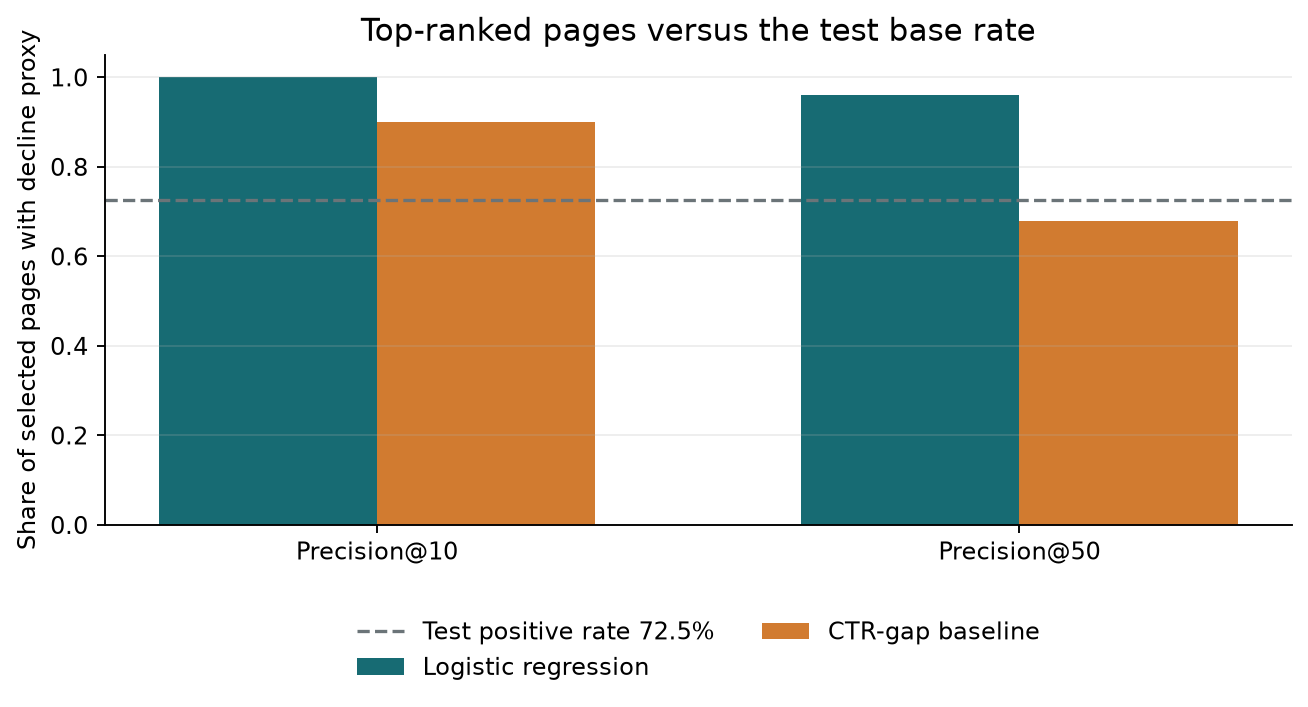

capstone permutation importance.png


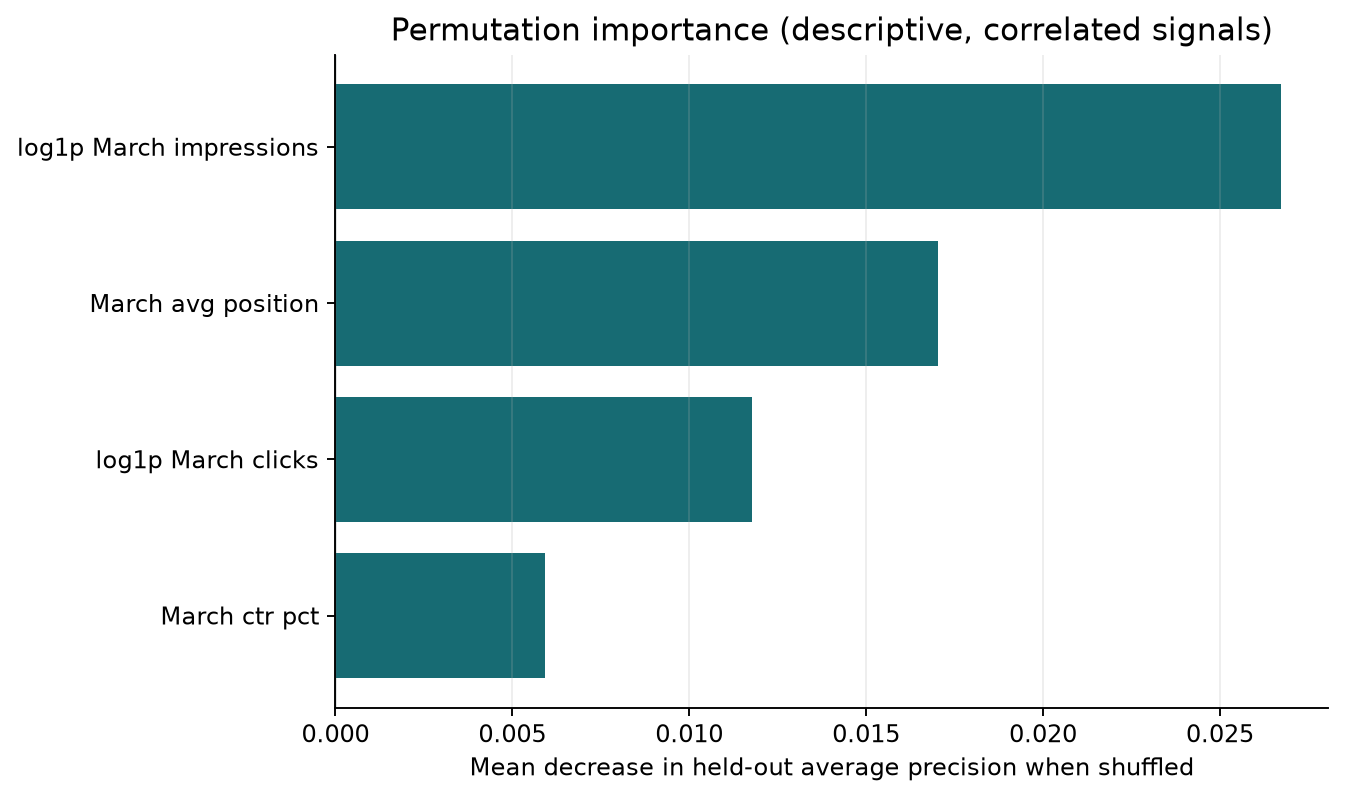

In [7]:
for chart in [
    "capstone_precision_recall.png",
    "capstone_precision_at_k.png",
    "capstone_permutation_importance.png",
]:
    print(chart.replace("_", " "))
    display(Image(filename=str(ROOT / "work/figures" / chart)))

In [8]:
importance = pd.DataFrame(metrics["permutation_importance"]).rename(columns={
    "feature": "March-only feature",
    "mean_ap_decrease": "Mean decrease in average precision",
    "std": "Standard deviation",
})
display(importance.round(4))
errors = metrics["top_risk_aggregates"]
print(f"At the descriptive 0.5 threshold: {errors['false_positives_at_0_5']:,} false positives and {errors['false_negatives_at_0_5']:,} false negatives on held-out rows.")

,March-only feature,Mean decrease in average precision,Standard deviation
0,log1p_march_impressions,0.0267,0.0046
1,march_avg_position,0.0170,0.0010
2,log1p_march_clicks,0.0118,0.0015
3,march_ctr_pct,0.0059,0.0011


At the descriptive 0.5 threshold: 1,838 false positives and 5,388 false negatives on held-out rows.


## 7. Limitations and honest framing

- The 20% month-over-month decline is noisy; seasonality, demand, SERP changes, and tracking shifts can trigger it without an editorial problem.
- This is one adjacent month pair and one client-grouped split. The training and test positive rates differ, which limits generalization claims to future cohorts or periods.
- Thirty-five clients remain in the eligible data; pages from one client share market and measurement context even though clients do not overlap across split partitions.
- Page-level April rows missing for a client active in April are treated as zero clicks. This may misclassify items.
- Class-balanced logistic scores are not calibrated probabilities. ROC-AUC is near chance, and the model's AP lift over the random reference is modest.
- The data does not show that editing a page causes traffic recovery, and this model does not predict Google's ranking algorithm.

## 8. Ranked recommendations and action guardrails

1. **Use a human-reviewed top-risk queue.** Compare the model score with the transparent CTR-gap reason; do not automate edits.
2. **Verify measurement and seasonality first.** Check both months' GSC coverage, demand changes, and SERP conditions.
3. **Inspect the page and intent.** A reviewer checks relevance, snippet fit, technical status, and the actual search context.
4. **Evaluate changes prospectively.** Record the edit date and use a suitable control or time-aware design before claiming improvement.

The saved action summary is aggregate-only. The report and public page contain no client/page identifiers, URLs, titles, or raw queries.

In [9]:
data = metrics["data"]
checks = {
    "Only March/April partitions used": metrics["source"]["partition_rows_scanned_in_analysis"],
    "Client start-date rule": data["client_history_start_filter"],
    "Clients with known starts by cutoff": f"{data['dimension_clients_started_by_cutoff']} / {data['dimension_clients']}",
    "Unknown / later starts excluded": f"{data['dimension_clients_missing_start_date']} / {data['dimension_clients_started_after_cutoff']}",
    "Minimum March impressions": data["minimum_march_impressions"],
    "Duplicate daily grain groups (March / April)": f"{data['march_duplicate_daily_grain_groups']} / {data['april_duplicate_daily_grain_groups']}",
    "Row-level exports written": metrics["outputs"]["row_level_exports_written"],
}
display(pd.Series(checks, name="Verified pipeline check"))

Only March/April partitions used                        March and April 2026 partitions only
Client start-date rule                          gsc_data_start is not null and <= 2026-03-01
Clients with known starts by cutoff                                                 52 / 104
Unknown / later starts excluded                                                      37 / 15
Minimum March impressions                                                                100
Duplicate daily grain groups (March / April)                                           0 / 0
Row-level exports written                                                              False
Name: Verified pipeline check, dtype: object

## 9. Artifacts, reproducibility, and paper link

The pipeline writes the report, metrics JSON, held-out aggregate action summary, and three charts. Run from the target repository after accepting the dataset terms and setting the Hugging Face read token in the `HF_TOKEN` environment variable:

```bash
python -m pip install -r requirements.txt
python work/scripts/run_capstone.py --source warehouse
```

The fixed random seed is 42. The notebook calls the same target-local script. The repository is https://github.com/Safin44/my-flyrank-ml-internship. This notebook performs no deployment or assignment submission.

In [10]:
artifact_paths = [
    "docs/index.html",
    "work/capstone_report.md",
    "work/outputs/capstone_metrics.json",
    "work/outputs/capstone_action_summary.json",
    "work/figures/capstone_precision_recall.png",
    "work/figures/capstone_precision_at_k.png",
    "work/figures/capstone_permutation_importance.png",
]
for rel in artifact_paths:
    path = ROOT / rel
    print(f"{'OK' if path.is_file() and path.stat().st_size > 0 else 'MISSING'}  {rel}  ({path.stat().st_size if path.exists() else 0:,} bytes)")

OK  docs/index.html  (14,722 bytes)
OK  work/capstone_report.md  (9,233 bytes)
OK  work/outputs/capstone_metrics.json  (5,968 bytes)
OK  work/outputs/capstone_action_summary.json  (491 bytes)
OK  work/figures/capstone_precision_recall.png  (71,309 bytes)
OK  work/figures/capstone_precision_at_k.png  (57,560 bytes)
OK  work/figures/capstone_permutation_importance.png  (53,560 bytes)


## Self-check before hand-in

Confirm the script completed top to bottom, clients do not overlap, daily grain is unique, the minimum-volume and history rules are applied, only aggregate outputs were saved, and the report reflects this run. No deployment or submission is performed here.

In [11]:
assert split["client_overlap"] == 0, "Client leakage: train/test overlap is not zero."
assert data["minimum_march_impressions"] == 100
assert data["march_duplicate_daily_grain_groups"] == 0
assert data["april_duplicate_daily_grain_groups"] == 0
assert metrics["outputs"]["row_level_exports_written"] is False
assert metrics["source"]["feature_partition"] == "2026-03"
assert metrics["source"]["label_partition"] == "2026-04"
assert metrics["features"]["feature_window"] == "March 2026 only"
print("Self-check passed: group split, cohort filters, grain probes, feature window, and aggregate-only outputs are verified.")

Self-check passed: group split, cohort filters, grain probes, feature window, and aggregate-only outputs are verified.


## ML-12 closing cells — five-minute demo outline

- **0:00–0:30 — Decision:** explain the human review queue and 20% click-decline proxy.
- **0:30–1:15 — Data:** show the gated warehouse source, March features/April label, history-start filter, 100-impression floor, and privacy safeguards.
- **1:15–2:00 — Baseline and model:** explain the within-position CTR-gap rule and the four March-only logistic-regression features.
- **2:00–2:45 — Validation:** show the 26/9-client grouped split, zero overlap, grain checks, and leakage exclusions.
- **2:45–3:45 — Results:** compare AP, ROC-AUC, Precision@50, and the test base rate; point out the modest AP gain and near-chance ROC-AUC.
- **3:45–4:30 — Honest limits:** discuss the training/test prevalence shift, single adjacent month pair, noisy labels, and zero-click assumption for missing page rows.
- **4:30–5:00 — Action:** recommend a human review, measurement checks, prospective evaluation, then preserve the aggregate report and notebook.

In [12]:
repository_url = "https://github.com/Safin44/my-flyrank-ml-internship"
post = (
    f"Can March-only search signals help prioritize pages for review? On {data['eligible_rows']:,} eligible page-client items from {data['eligible_clients']} clients, "
    f"a client-held-out logistic model reached AP {model['average_precision']:.3f} vs {baseline['average_precision']:.3f} for a transparent CTR-gap baseline; "
    f"ROC-AUC was {model['roc_auc']:.3f}, so this is modest, directional evidence—not a traffic forecast or causal claim. "
    f"I used March-only features and a 25% client-group holdout; the held-out decline rate was {split['test_positive_rate']:.1%}. Repository: {repository_url}"
)
print(post)

Can March-only search signals help prioritize pages for review? On 63,498 eligible page-client items from 35 clients, a client-held-out logistic model reached AP 0.759 vs 0.708 for a transparent CTR-gap baseline; ROC-AUC was 0.530, so this is modest, directional evidence—not a traffic forecast or causal claim. I used March-only features and a 25% client-group holdout; the held-out decline rate was 72.5%. Repository: https://github.com/Safin44/my-flyrank-ml-internship


In [13]:
employer_summary = [
    f"I built a reproducible, aggregate-only capstone that ranks pages for human review using March-only search signals and a client-grouped holdout.",
    f"It analyzes {data['eligible_rows']:,} eligible client-content items across {data['eligible_clients']} clients from the gated FlyRank anonymized warehouse, comparing logistic regression with a transparent CTR-gap baseline.",
    f"The model's AP was {model['average_precision']:.3f} versus {baseline['average_precision']:.3f} for the baseline, but ROC-AUC was {model['roc_auc']:.3f} and train/test prevalence shifted, so the evidence is directional and not causal."
]
assert len(employer_summary) == 3
print("\n".join(employer_summary))

I built a reproducible, aggregate-only capstone that ranks pages for human review using March-only search signals and a client-grouped holdout.
It analyzes 63,498 eligible client-content items across 35 clients from the gated FlyRank anonymized warehouse, comparing logistic regression with a transparent CTR-gap baseline.
The model's AP was 0.759 versus 0.708 for the baseline, but ROC-AUC was 0.530 and train/test prevalence shifted, so the evidence is directional and not causal.


### Final review checklist

- [x] Question, data scope, methods, same-split results, limitations, and ranked recommendations documented by the target pipeline.
- [x] Three figures generated and referenced by the report and notebook.
- [x] Repository-only artifacts contain aggregate metrics and no row-level identifiers.
- [ ] **Owner action:** review the fresh aggregate outputs before any separate hand-in decision.